In [15]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import ScalarFormatter
%matplotlib inline
import pandas as pd
from planet_cookbook import read_reports as rr
import os
import rebound
import seaborn as sns

sol_to_earth = 332946.078
G = 6.6743* 10**(-11) #N⋅m2/kg2
M_sun = 1.989e+33 #g
AU = 1.496e+13 #cm

params = {
   'axes.labelsize': 20,
   'font.size': 20,
   'legend.fontsize': 10,
   'xtick.labelsize': 20,
   'ytick.labelsize': 15,
   'text.usetex': True, #to use TeX in your labels
   'font.family':'serif',
   'axes.titlesize': 15
   }
rcParams.update(params)

In [16]:
solar_system_df = pd.read_csv('../solarsystem.csv')
mercury = solar_system_df[solar_system_df['name'] == 'Mercury']
venus = solar_system_df[solar_system_df['name'] == 'Venus']
earth = solar_system_df[solar_system_df['name'] == 'Earth']
mars = solar_system_df[solar_system_df['name'] == 'Mars']

In [17]:
def planet_dev_index(simulated_planets, ref_planet, a_range):
    a_ref_planet = ref_planet['a'].values[0]
    m_ref_planet = ref_planet['m'].values[0]
    cmf_ref_planet = ref_planet['CMF'].values[0]
    rep_planets = simulated_planets[(simulated_planets['semi'] < a_ref_planet + a_range) & 
                                    (simulated_planets['semi'] > a_ref_planet - a_range)]
    
    masses = simulated_planets['mass'] * sol_to_earth
    cmfs = simulated_planets['cmf']
    
    cmf_diff = np.sum((cmfs - cmf_ref_planet)**2) / (np.average(cmfs) * len(cmfs))
    masses_diff = np.sum((masses - m_ref_planet)**2) / (np.average(masses) * len(masses))

    index = np.sqrt((cmf_diff + masses_diff))
    return index

#me is mercury, ve is venus, ea is earth, ma is mars
def solar_system_dev_index(simulated_planets, me, ve, ea, ma, a_range):
    planet_dev_inds = np.zeros(4)
    merc_dev_ind = planet_dev_index(simulated_planets, me, a_range)
    venus_dev_ind = planet_dev_index(simulated_planets, ve, a_range)
    earth_dev_ind = planet_dev_index(simulated_planets, ea, a_range)
    mars_dev_ind = planet_dev_index(simulated_planets, ma, a_range)
    solsys_dev_ind = np.average([merc_dev_ind, venus_dev_ind, earth_dev_ind, mars_dev_ind])
    return solsys_dev_ind

In [18]:
ueda_v5_full_df = pd.read_csv("../ueda_v5/ueda_v5_grid_fulldf.csv")
unique_bounds = ueda_v5_full_df['boundary'].unique()
unique_percs = ueda_v5_full_df['percentage'].unique()

In [19]:
# ...existing code...

# Prepare to collect results for all (boundary, percentage) sets
results = []
planet_dev_results = []
solsys_dev_results = []

for i, bound in enumerate(unique_bounds):
    for j, perc in enumerate(unique_percs):
        df_subset = ueda_v5_full_df[
            (ueda_v5_full_df['boundary'] == bound) &
            (ueda_v5_full_df['percentage'] == perc)
        ]
        # Save mean/std cmf as before
        for planet, a, color in zip(solar_system_df['name'], solar_system_df['a'], solar_system_df['color']):
            in_bin = (df_subset['semi'] >= a - 0.1) & (df_subset['semi'] <= a + 0.1)
            cmfs = df_subset.loc[in_bin, 'cmf']
            results.append({
                'boundary': bound,
                'percentage': perc,
                'planet': planet,
                'a_center': a,
                'mean_cmf': cmfs.mean(),
                'std_cmf': cmfs.std(),
                'n_in_bin': len(cmfs)
            })
        # Save planet_dev_index for each planet
        for planet, ref, a in zip(
            solar_system_df['name'],
            [mercury, venus, earth, mars],
            solar_system_df['a']
        ):
            idx = planet_dev_index(df_subset, ref, 0.1)
            planet_dev_results.append({
                'boundary': bound,
                'percentage': perc,
                'planet': planet,
                'dev_index': idx
            })
        # Save solar_system_dev_index for this grid cell
        solsys_idx = solar_system_dev_index(df_subset, mercury, venus, earth, mars, 0.1)
        solsys_dev_results.append({
            'boundary': bound,
            'percentage': perc,
            'solsys_dev_index': solsys_idx
        })

# Save all results to CSVs
avg_cmf_df = pd.DataFrame(results)
avg_cmf_df.to_csv("average_cmf_grid_ueda_v5.csv", index=False)

planet_dev_df = pd.DataFrame(planet_dev_results)
planet_dev_df.to_csv("planet_dev_index_grid_ueda_v5.csv", index=False)

solsys_dev_df = pd.DataFrame(solsys_dev_results)
solsys_dev_df.to_csv("solsys_dev_index_grid_ueda_v5.csv", index=False)

/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:552: RuntimeWarning: Mean of empty slice.
  avg = a.mean(axis, **keepdims_kw)
/Users/honeyeah/miniconda3/envs/haniyeh_research/lib/python3.13/site-packages/numpy/_core/_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


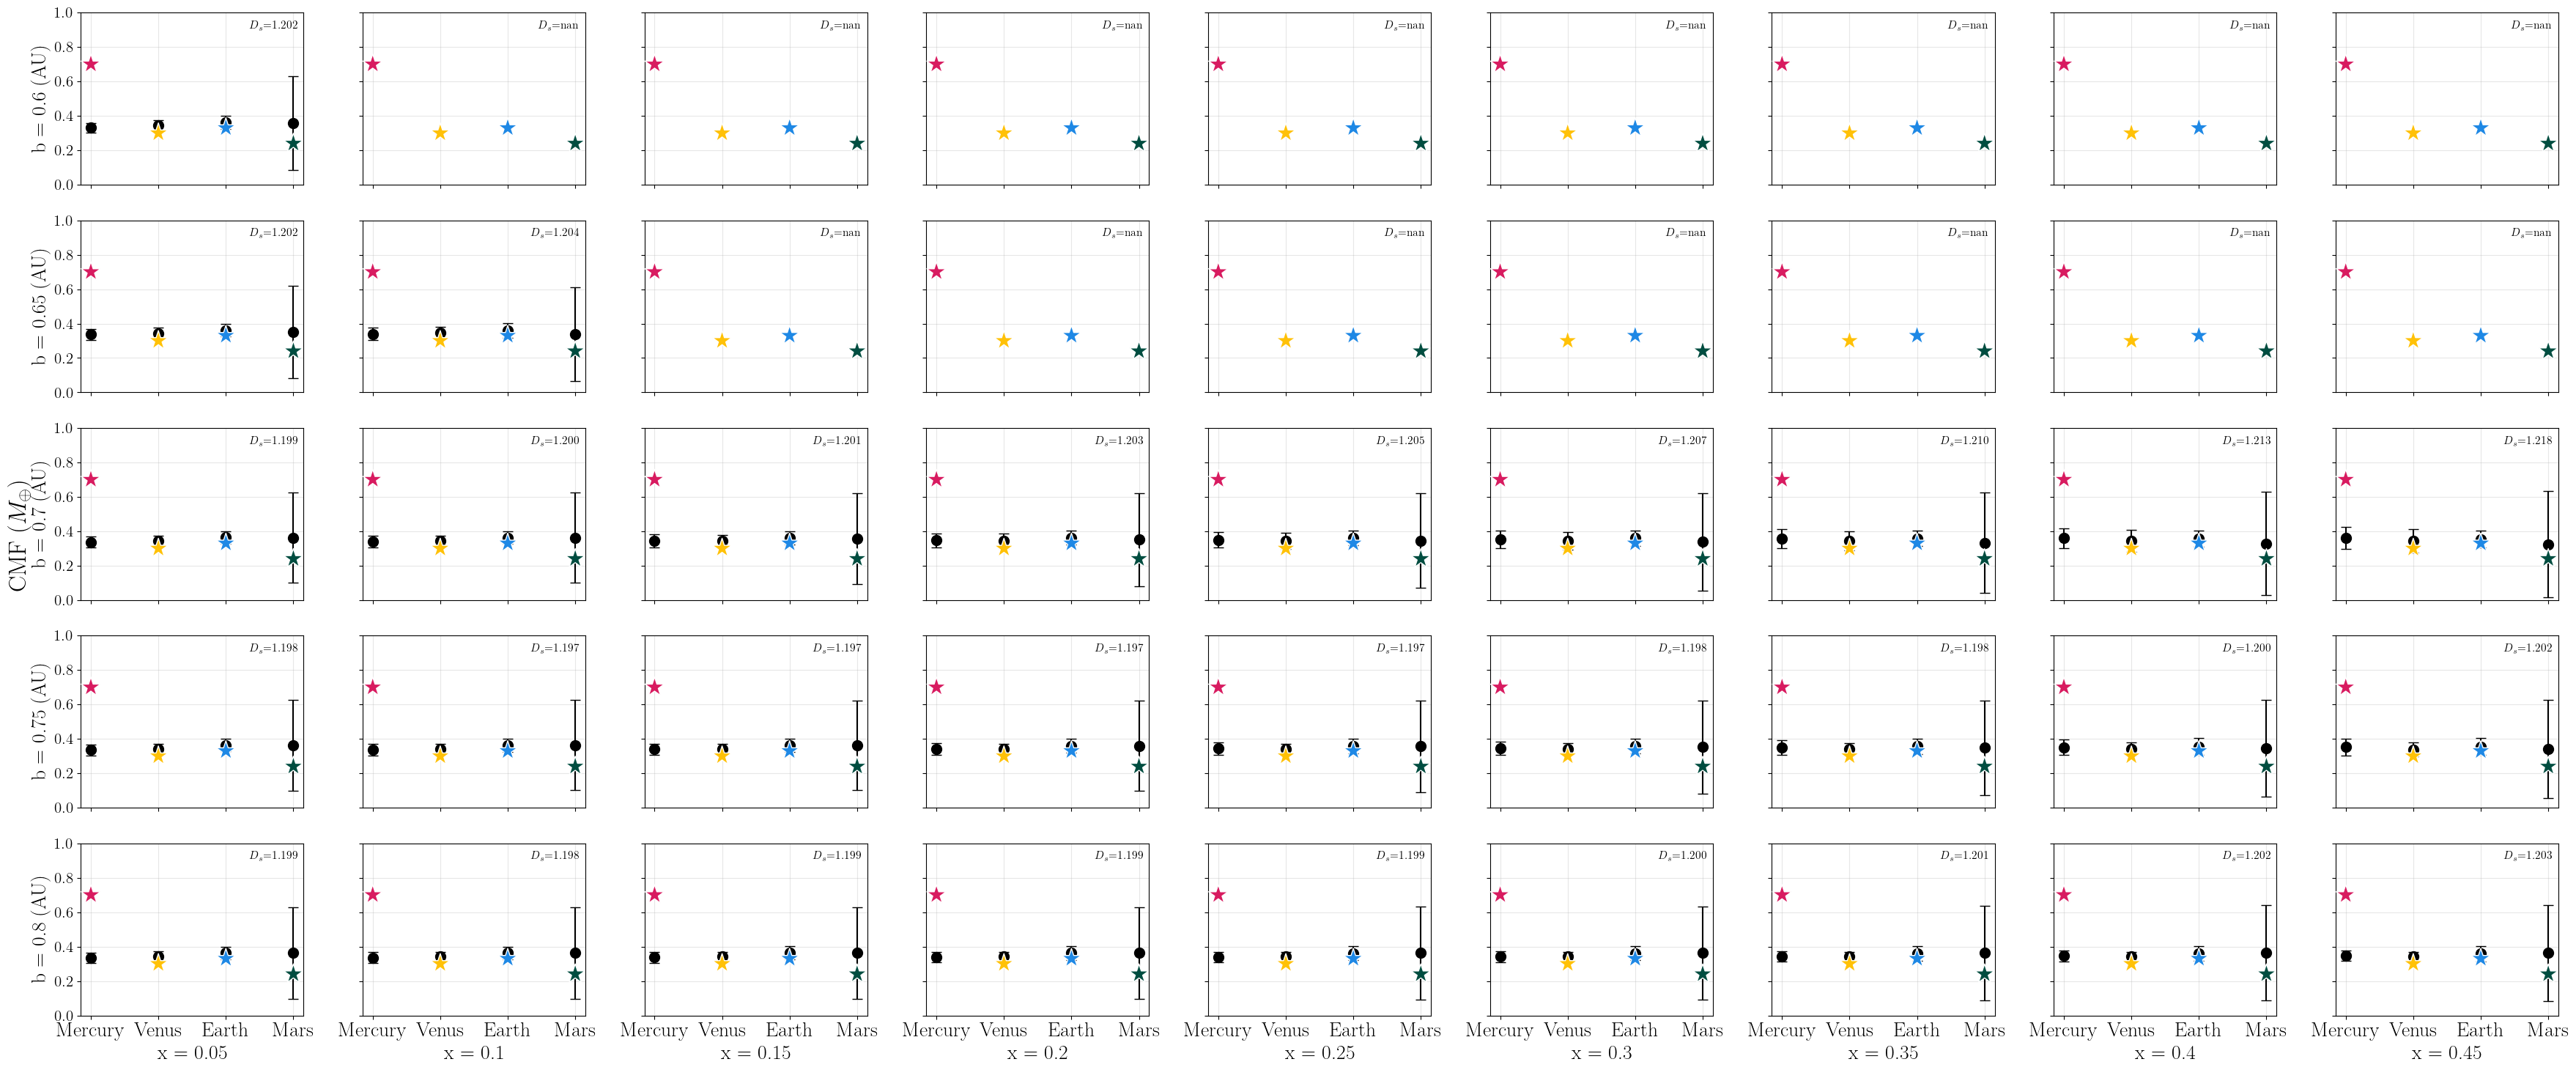

In [24]:
# ...existing code...

# Load the solar system dev index grid
solsys_dev_df = pd.read_csv("solsys_dev_index_grid_ueda_v5.csv")
planet_names = ['Mercury', 'Venus', 'Earth', 'Mars']
planet_colors = solar_system_df['color']
real_cmfs = solar_system_df['CMF']


fig, axes = plt.subplots(len(unique_bounds), len(unique_percs),
                         figsize=(4 * len(unique_percs), 3 * len(unique_bounds)),
                         sharex=True, sharey=True)


for i, bound in enumerate(unique_bounds):
    for j, perc in enumerate(unique_percs):
        ax = axes[i][j] if len(unique_bounds) > 1 else (axes[j] if len(unique_percs) > 1 else axes)
        df_sub = avg_cmf_df[(avg_cmf_df['boundary'] == bound) & (avg_cmf_df['percentage'] == perc)]
        means = [df_sub[df_sub['planet'] == p]['mean_cmf'].values[0] for p in planet_names]
        stds = [df_sub[df_sub['planet'] == p]['std_cmf'].values[0] for p in planet_names]
        x = np.arange(len(planet_names))
        # Plot simulated means with errorbars
        ax.errorbar(x, means, yerr=stds, fmt='o', color='k', capsize=5, markersize = 10)
        # Plot real values as stars
        ax.scatter(x, real_cmfs, color=planet_colors, s=400, marker='*', edgecolor='white', zorder=5)
        ax.set_xticks(x)
        ax.set_xticklabels(planet_names)
        ax.set_ylim(0, 1)
        ax.grid(True, alpha=0.3)
        if i == len(unique_bounds) - 1:
            ax.set_xlabel(f"x = {perc}")
        if j == 0:
            ax.set_ylabel(f"b = {bound} (AU)")
        # Annotate solsys_dev_index at top right
        solsys_idx = solsys_dev_df[
            (solsys_dev_df['boundary'] == bound) &
            (solsys_dev_df['percentage'] == perc)
        ]['solsys_dev_index'].values[0]
        ax.annotate(r"$D_{s}$" + f"={solsys_idx:.3f}",
                    xy=(0.97, 0.95), xycoords='axes fraction',
                    ha='right', va='top', fontsize=11)
                    #bbox=dict(boxstyle="round,pad=0.2", fc="w", alpha=0.7))

#fig.suptitle('Average CMF for each planet\nfor each (boundary, percentage) set', fontsize=18, y=1.02)
fig.supylabel(r'CMF ($M_\oplus$)', fontsize=24, x=0.02)
plt.tight_layout()
#plt.savefig('paper_plots/solarsystem_compare_with_devs.pdf', dpi=300)

plt.show()